# Phase 2: Data Preparation & Exploratory Data Analysis (`02_data_preparation_and_eda.ipynb`)

**Project:** Smart Manufacturing – Intelligent Process Quality Analysis and Predictive Defect Detection Using Machine Learning

**Scope:** Reuse Phase 1 `load_raw_secom()`, validate integrity and timestamps, apply reproducible unsupervised cleaning, compute descriptive statistics and feature rankings, inspect correlations/outliers, and interpret visualisations. *(No ML model training or dashboarding in Phase 2.)*

In [1]:
import json
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from secom_project.data_validation import validate_secom_raw, load_and_parse_raw_secom
from secom_project.data_cleaning import clean_secom_data, write_data_quality_report
from secom_project.eda import run_eda

## 1. Validation Using Phase 1 `load_raw_secom()`

In [2]:
validation = validate_secom_raw()
print('Dimensions:', validation['dimensions'])
print('Target validation:', validation['target_validation'])
print('Timestamp validation:', validation['timestamp_validation'])
print('Duplicates:', validation['data_quality']['duplicate_full_rows'], 'full rows,', validation['data_quality']['non_constant_duplicate_column_groups'], 'non-const dup col groups')

Dimensions: {'rows': 1567, 'sensor_columns': 590, 'label_columns': 2, 'row_alignment_verified': True}
Target validation: {'missing_target_labels': 0, 'valid_labels_only_minus1_and_1': True, 'pass_count_minus1': 1463, 'fail_count_1': 104, 'pass_pct': 93.3631, 'fail_pct': 6.6369, 'imbalance_ratio_pass_to_fail': 14.0673}
Timestamp validation: {'missing_timestamp_raw': 0, 'failed_timestamp_parses': 0, 'format': '%d/%m/%Y %H:%M:%S', 'min_timestamp': '2008-07-19 11:55:00', 'max_timestamp': '2008-10-17 06:07:00', 'is_monotonic_non_decreasing_in_raw_order': True, 'unique_timestamps': 1534, 'repeated_timestamp_groups': 32, 'rows_sharing_repeated_timestamp': 65}
Duplicates: 0 full rows, [] non-const dup col groups


## 2. Reproducible Data Preparation, Missingness & Outlier Audit

In [3]:
sensors_df, labels_df = load_and_parse_raw_secom()
cleaned_df, missing_report_df, cleaning_summary = clean_secom_data(sensors_df, labels_df)
print('Raw shape:', cleaning_summary['raw_shape'])
print('Cleaned shape:', cleaning_summary['cleaned_shape'])
print('Transformations:', json.dumps(cleaning_summary['transformations'], indent=2))
print('Non-destructive IQR outlier audit:', json.dumps({k: v for k, v in cleaning_summary['outlier_audit_non_destructive'].items() if k != 'top_extreme_outlier_features'}, indent=2))
pd.DataFrame(cleaning_summary['threshold_impact_analysis'])

Raw shape: {'rows': 1567, 'sensor_columns': 590}
Cleaned shape: {'rows': 1567, 'total_columns': 443, 'sensor_columns': 440, 'target_and_timestamp_columns': ['target_label', 'timestamp', 'timestamp_raw']}
Transformations: {
  "infinite_values_found_and_replaced": 0,
  "duplicate_sensor_rows_found": 0,
  "duplicate_full_rows_removed": 0,
  "records_removed_excessive_missingness": 0,
  "max_observed_record_missing_pct": 25.7627,
  "constant_features_removed": 116,
  "near_constant_features_removed": 6,
  "high_missing_features_removed": 28,
  "duplicate_non_constant_features_removed": 0,
  "total_unique_features_removed": 150,
  "retained_sensor_features": 440
}
Non-destructive IQR outlier audit: {
  "evaluated_active_features_with_positive_iqr": 436,
  "zero_iqr_active_features": 4,
  "non_null_cells_evaluated": 672380,
  "iqr_1_5_outlier_cells": 23672,
  "iqr_1_5_outlier_pct": 3.5206,
  "iqr_3_0_extreme_outlier_cells": 8420,
  "iqr_3_0_extreme_outlier_pct": 1.2523,
  "records_with_any_e

,missing_cutoff_pct,features_exceeding_cutoff,total_removed_incl_const_and_nc,features_retained
0,20,32,154,436
1,40,32,154,436
2,50,28,150,440
3,60,24,146,444
4,80,8,130,460


## 3. Descriptive Statistics & Feature Rankings

In [4]:
eda_summary = run_eda()
stats_df = pd.read_csv(eda_summary['statistical_summary_csv'])
print('Statistical summary shape:', stats_df.shape)
print('Top 10 by Missingness:')
display(missing_report_df.sort_values(['missing_count', 'feature'], ascending=[False, True]).head(10)[['missingness_rank', 'feature', 'missing_count', 'missing_pct', 'cleaning_action']])
print('Top 10 by Variance:')
display(stats_df.sort_values('variance', ascending=False).head(10)[['variance_rank', 'feature', 'variance', 'std', 'range', 'skewness']])
print('Top 10 by Unique Values:')
display(stats_df.sort_values('n_unique_non_null_raw', ascending=False).head(10)[['unique_values_rank', 'feature', 'n_unique_non_null_raw', 'mode', 'mode_count']])

Statistical summary shape: (440, 42)
Top 10 by Missingness:


,missingness_rank,feature,missing_count,missing_pct,cleaning_action
157,1,sensor_157,1429,91.1934,Removed (High Missingness >50%)
158,1,sensor_158,1429,91.1934,Removed (High Missingness >50%)
292,1,sensor_292,1429,91.1934,Removed (High Missingness >50%)
293,1,sensor_293,1429,91.1934,Removed (High Missingness >50%)
85,5,sensor_085,1341,85.5775,Removed (High Missingness >50%)
220,5,sensor_220,1341,85.5775,Removed (High Missingness >50%)
358,5,sensor_358,1341,85.5775,Removed (High Missingness >50%)
492,5,sensor_492,1341,85.5775,Removed (High Missingness >50%)
109,9,sensor_109,1018,64.9649,Removed (High Missingness >50%)
110,9,sensor_110,1018,64.9649,Removed (High Missingness >50%)


Top 10 by Variance:


,variance_rank,feature,variance,std,range,skewness
144,1,sensor_162,4.290600e+07,6550.267099,36871.0000,1.830826
143,2,sensor_161,1.795094e+07,4236.854877,37943.0000,2.231968
235,3,sensor_297,1.040270e+07,3225.321542,18520.4683,1.792539
22,4,sensor_024,8.414911e+06,2900.846582,28910.5000,-0.054415
234,5,sensor_296,3.896667e+06,1973.997717,15559.9525,2.191674
21,6,sensor_023,1.902415e+06,1379.280633,12349.7500,0.356914
141,7,sensor_159,9.652254e+05,982.458855,7791.0000,4.206731
19,8,sensor_021,3.924158e+05,626.430997,7150.2500,2.375455
142,9,sensor_160,3.300005e+05,574.456703,4170.0000,3.996204
177,10,sensor_204,3.181198e+05,564.021108,9998.4054,17.635147


Top 10 by Unique Values:


,unique_values_rank,feature,n_unique_non_null_raw,mode,mode_count
101,1,sensor_115,1567,748.61150,1
203,2,sensor_250,1566,90.23880,2
234,3,sensor_296,1565,1202.41210,3
351,4,sensor_460,1564,35.81170,2
296,4,sensor_388,1564,28.04410,2
318,6,sensor_423,1563,69.90545,3
373,7,sensor_490,1562,66.01210,2
232,7,sensor_294,1562,278.67190,3
387,7,sensor_522,1562,12.24340,2
43,7,sensor_046,1562,725.91340,2


## 4. Pass vs. Fail Comparison & Visualisations (with Interpretations)

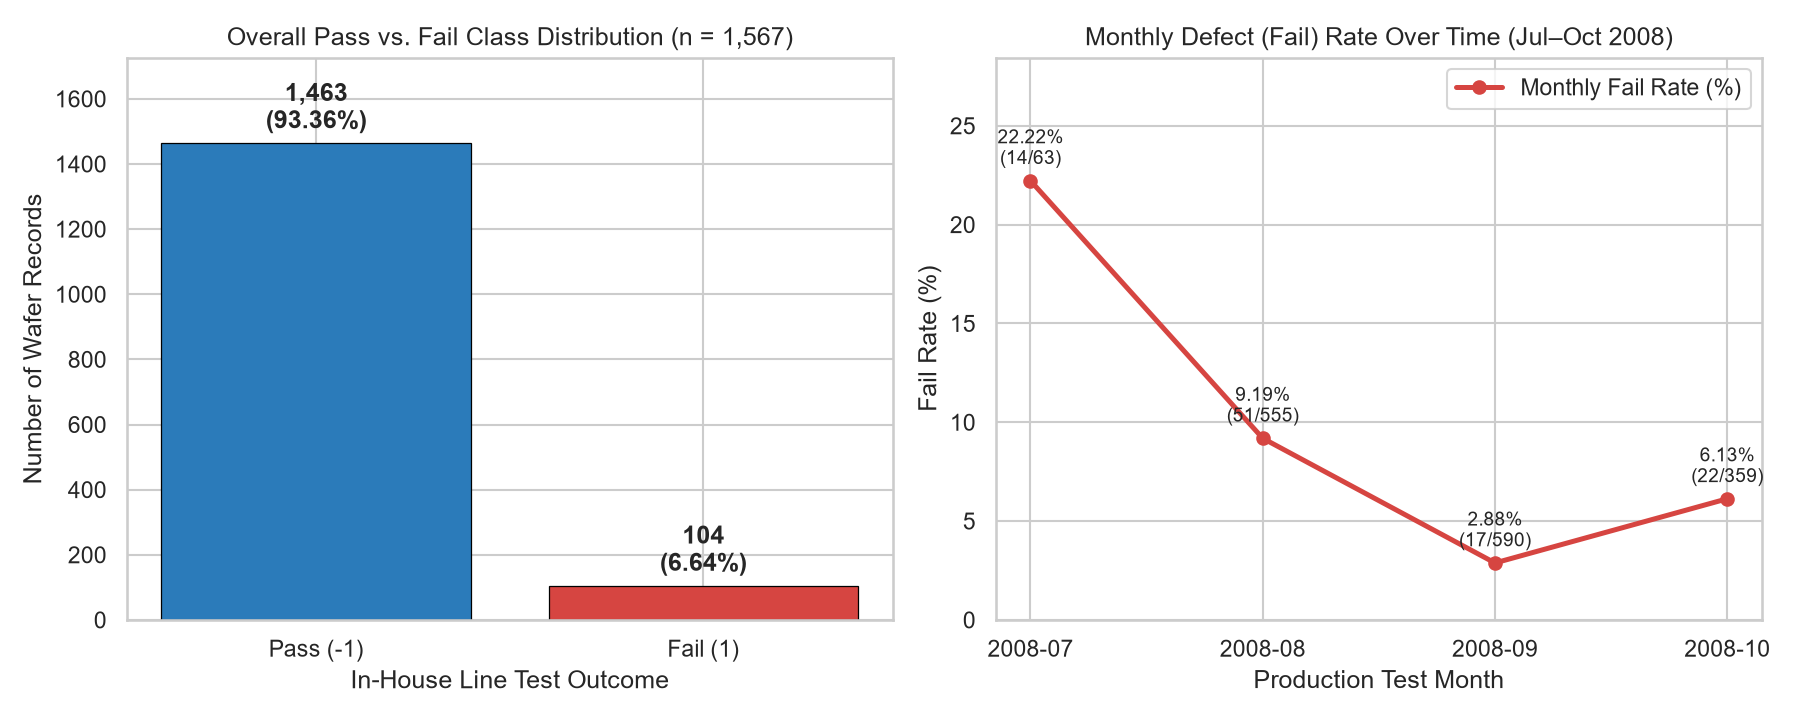

In [5]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/class_distribution.png')))

**Interpretation (`class_distribution.png`):** Pass (`-1`, `1,463` / `93.36%`) outnumbers Fail (`1`, `104` / `6.64%`) by `14.07 : 1`, while monthly defect rates swing from `22.22%` in Jul 2008 down to `2.88%` in Sep 2008 and `6.13%` in Oct 2008.

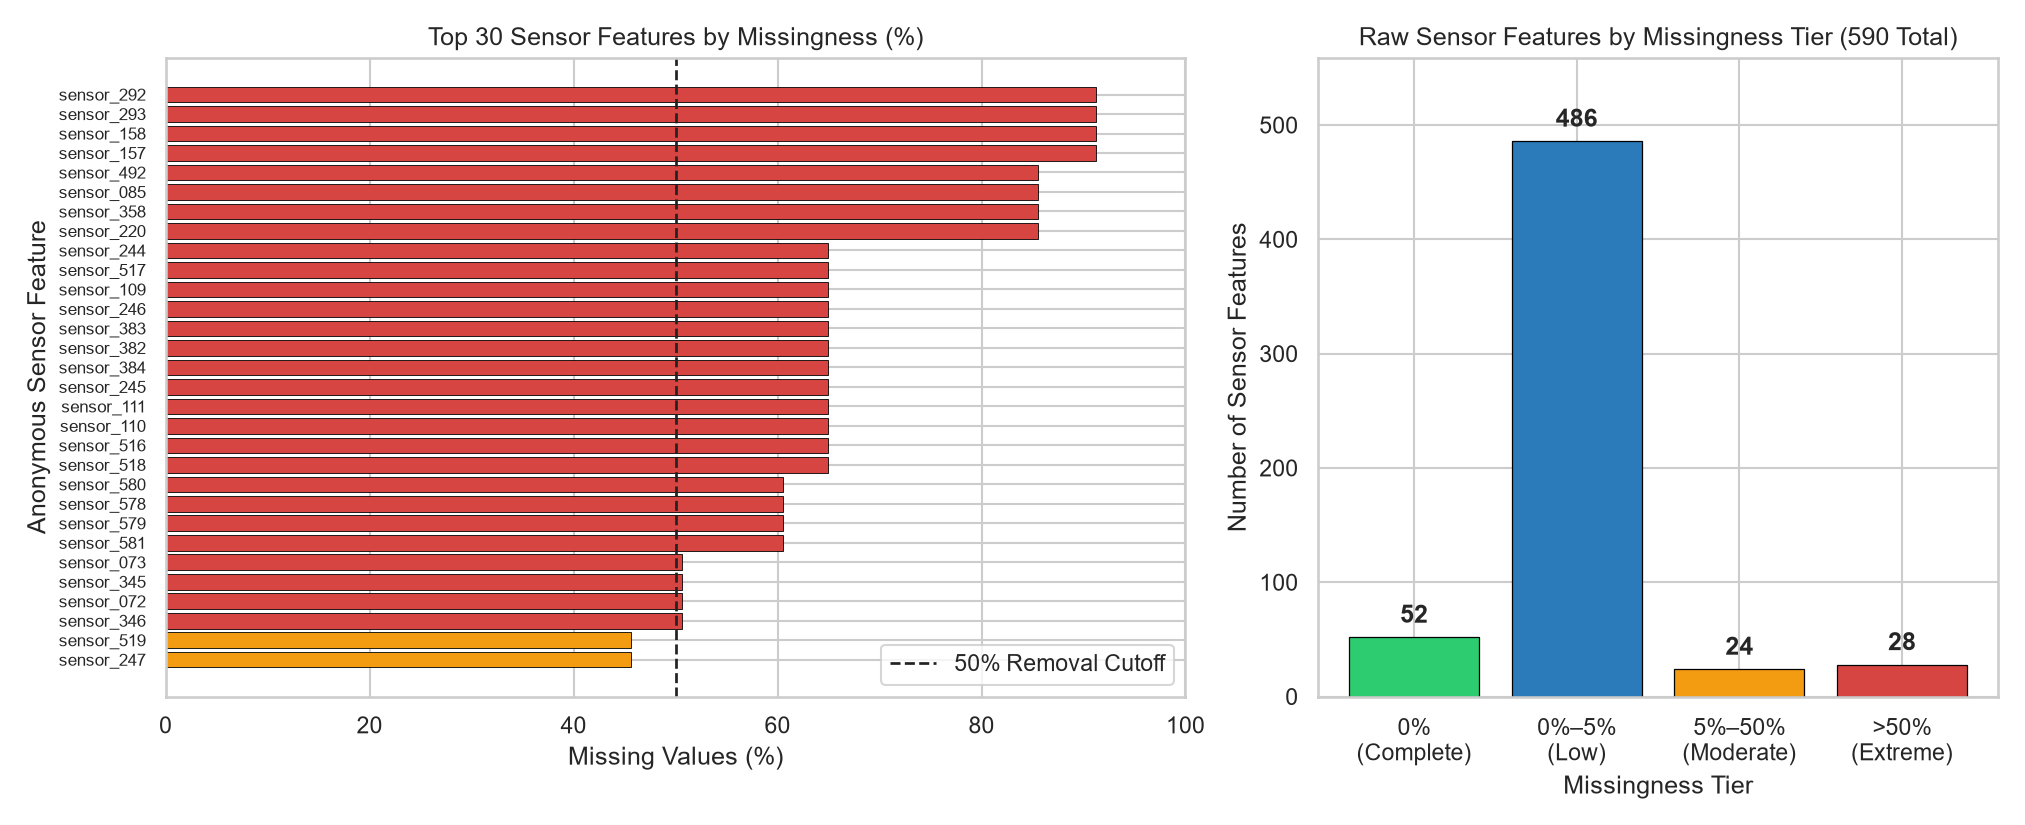

In [6]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/missing_values.png')))

**Interpretation (`missing_values.png`):** Missingness is structured across operational blocks; `28` sensors exceed `50%` missing (`50.67%`–`91.19%`) and are cleanly separated from the `4` moderate-missingness features at `45.63%`.

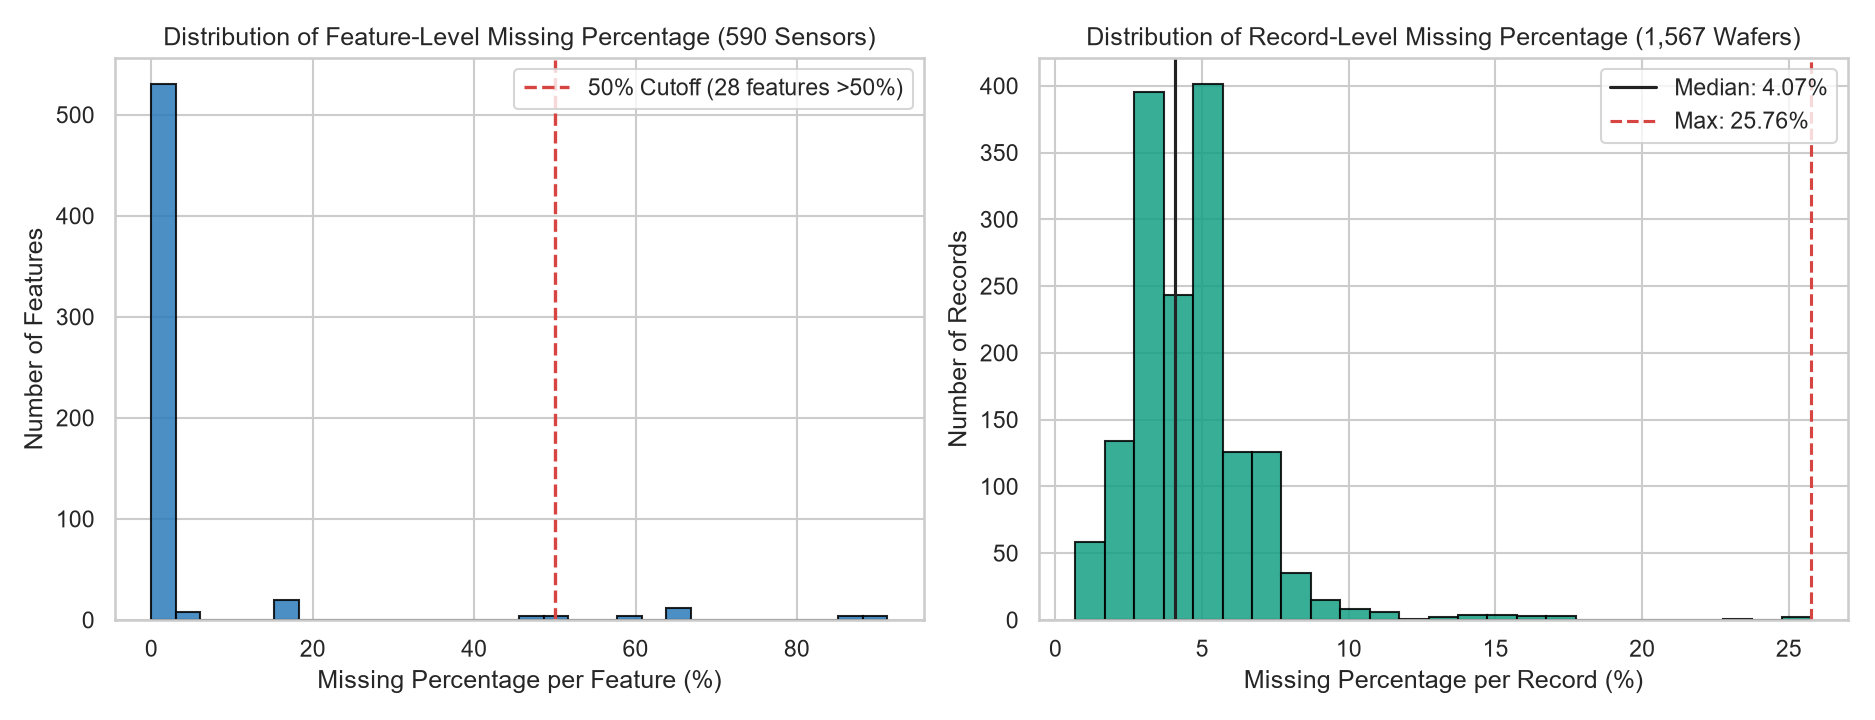

In [7]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/missing_percentage.png')))

**Interpretation (`missing_percentage.png`):** Most features (`538 / 590`) have `<= 5%` missingness, whereas `100%` of wafer records (`1,567 / 1,567`) have between `0.68%` and `25.76%` missing sensor readings (median `4.07%`), confirming row deletion is infeasible.

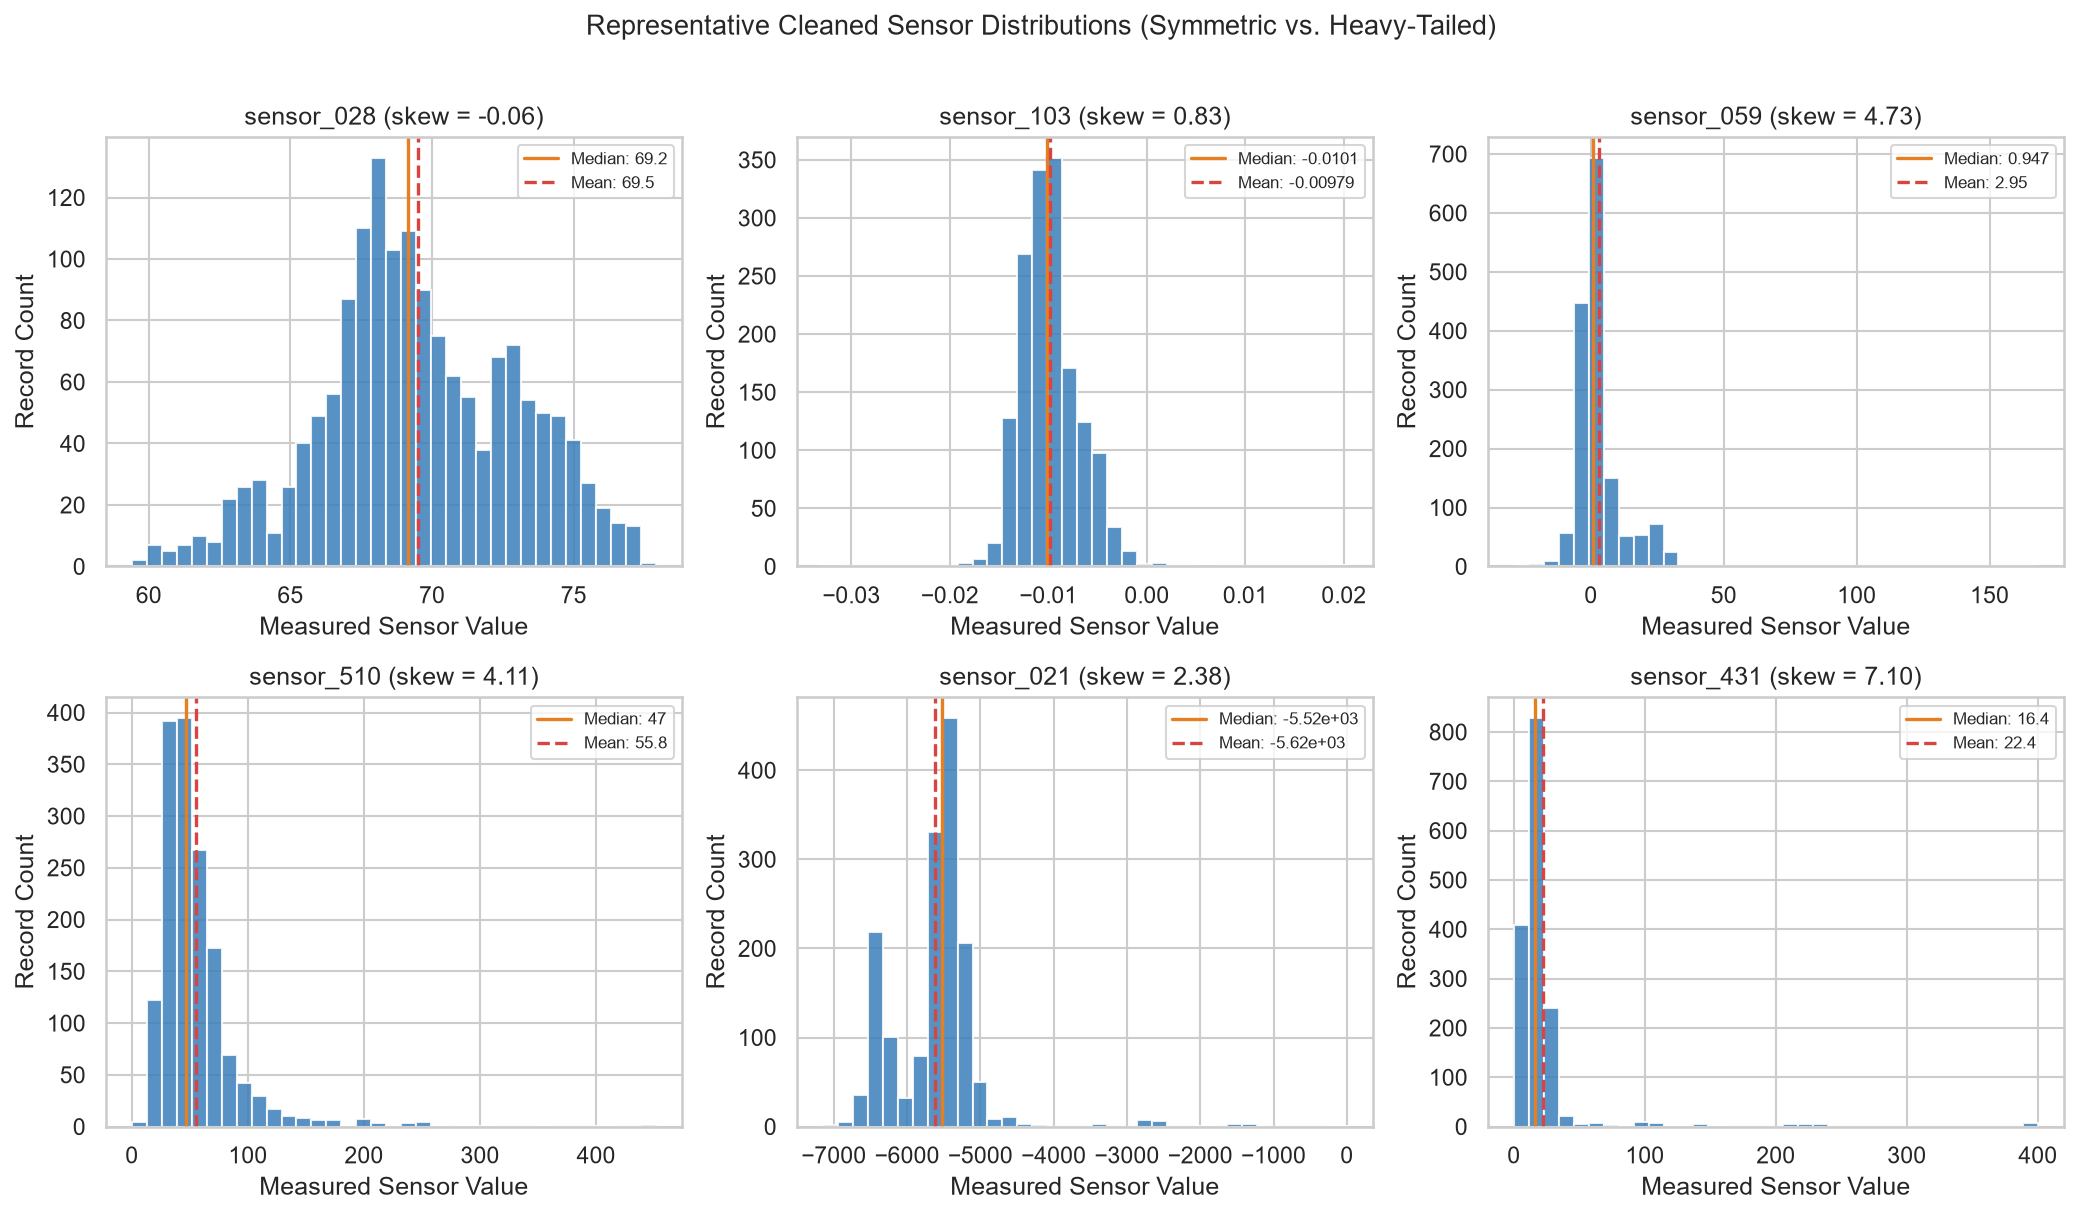

In [8]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/sensor_distributions.png')))

**Interpretation (`sensor_distributions.png`):** Sensors range from near-symmetric (`sensor_028`, `skew = -0.06`) to heavily right-skewed (`sensor_059` `skew = 4.73`, `sensor_510` `skew = 4.11`, `sensor_431` `skew = 7.10`), justifying median imputation and non-parametric tests.

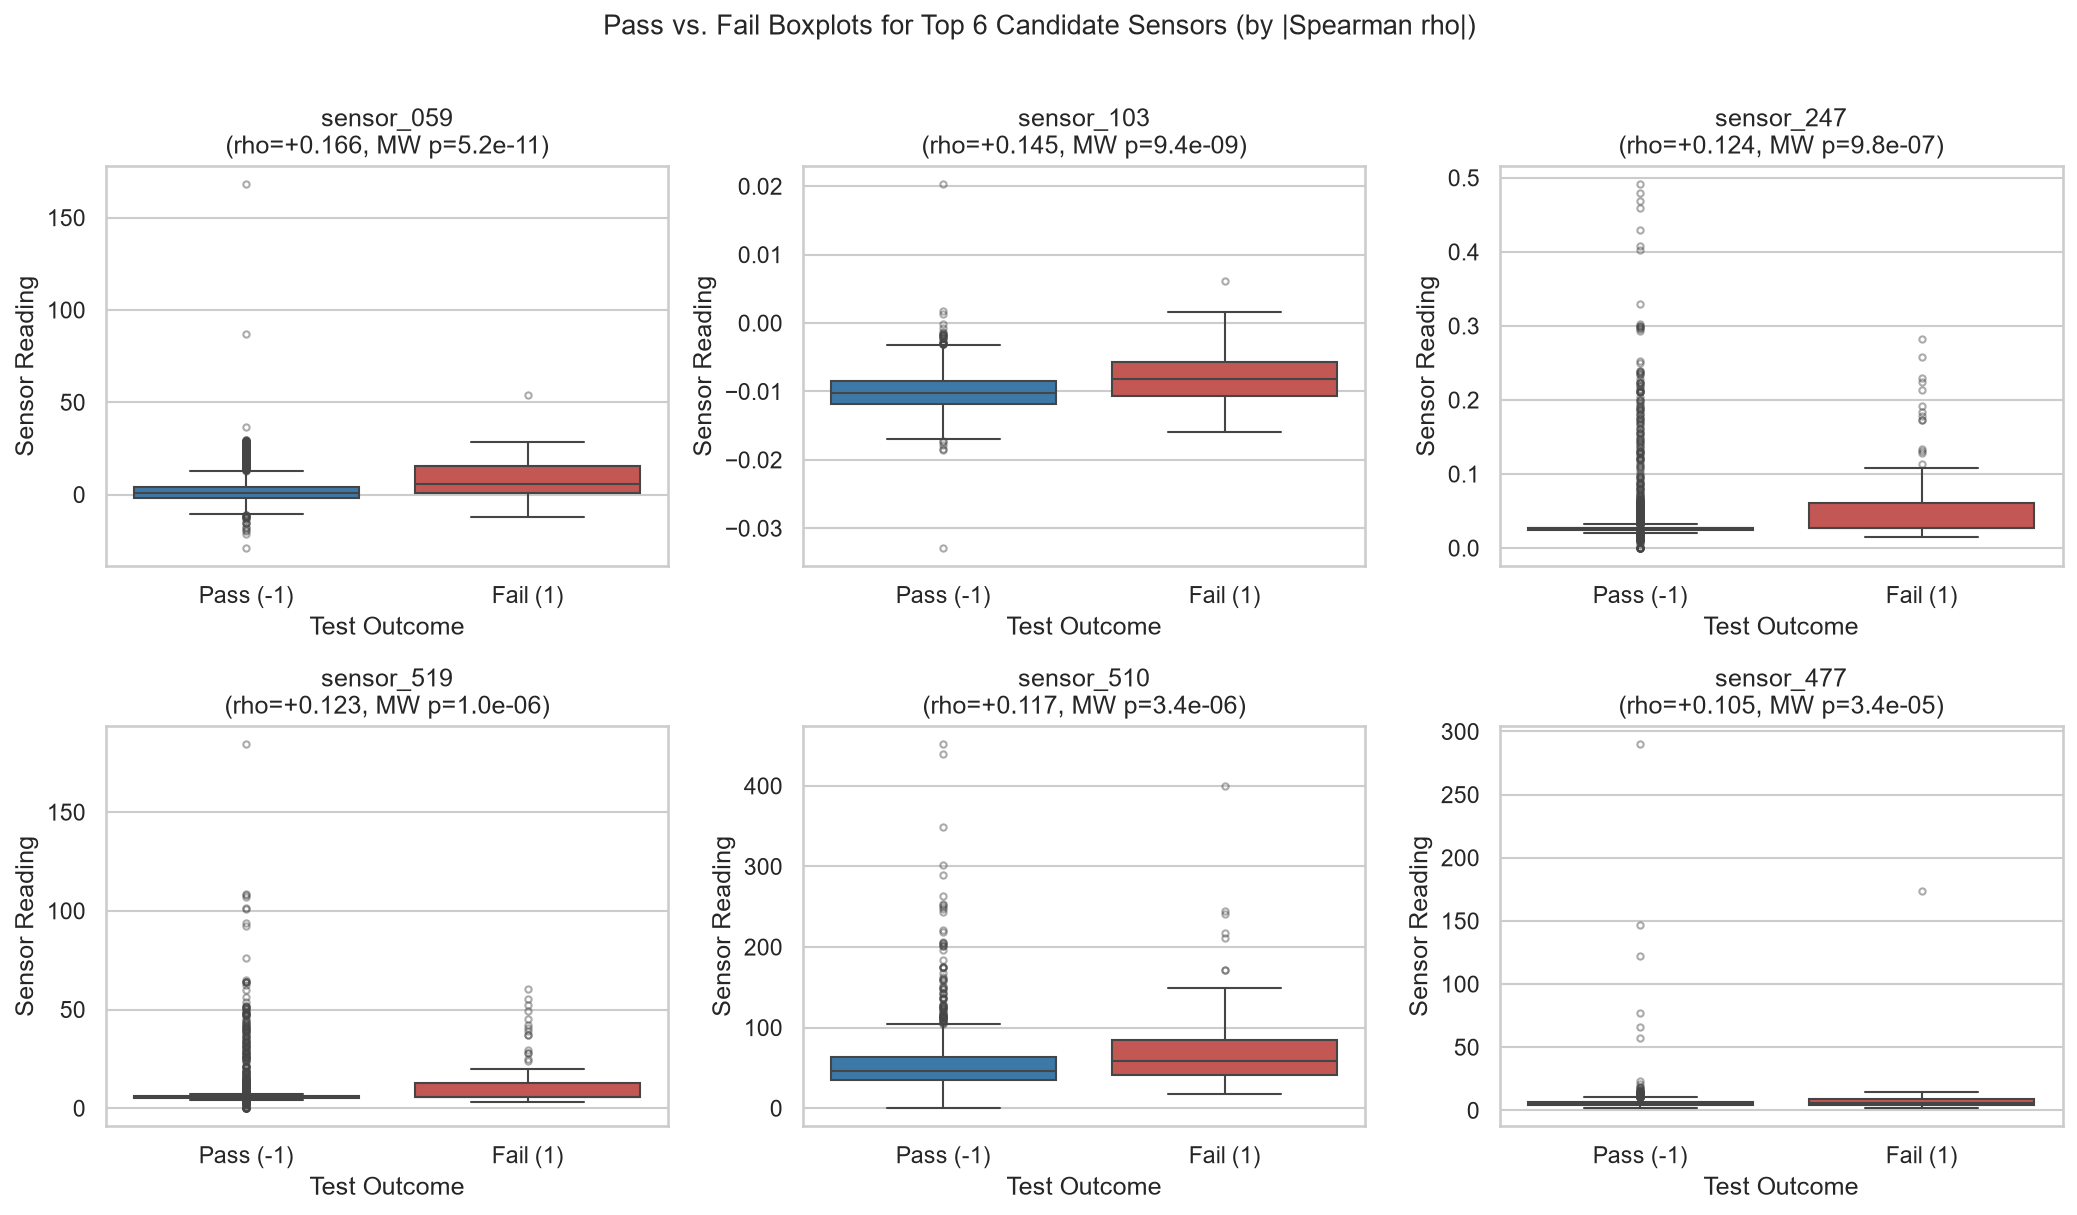

In [9]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/pass_fail_boxplots.png')))

**Interpretation (`pass_fail_boxplots.png`):** Top Spearman-ranked sensors (`sensor_059`, `sensor_103`, `sensor_510`) show elevated medians and wider upper tails in Fail wafers, while `sensor_247`/`sensor_519` illustrate median-imputation flattening where Pass missingness (`46.62%`) exceeded Fail missingness (`31.73%`).

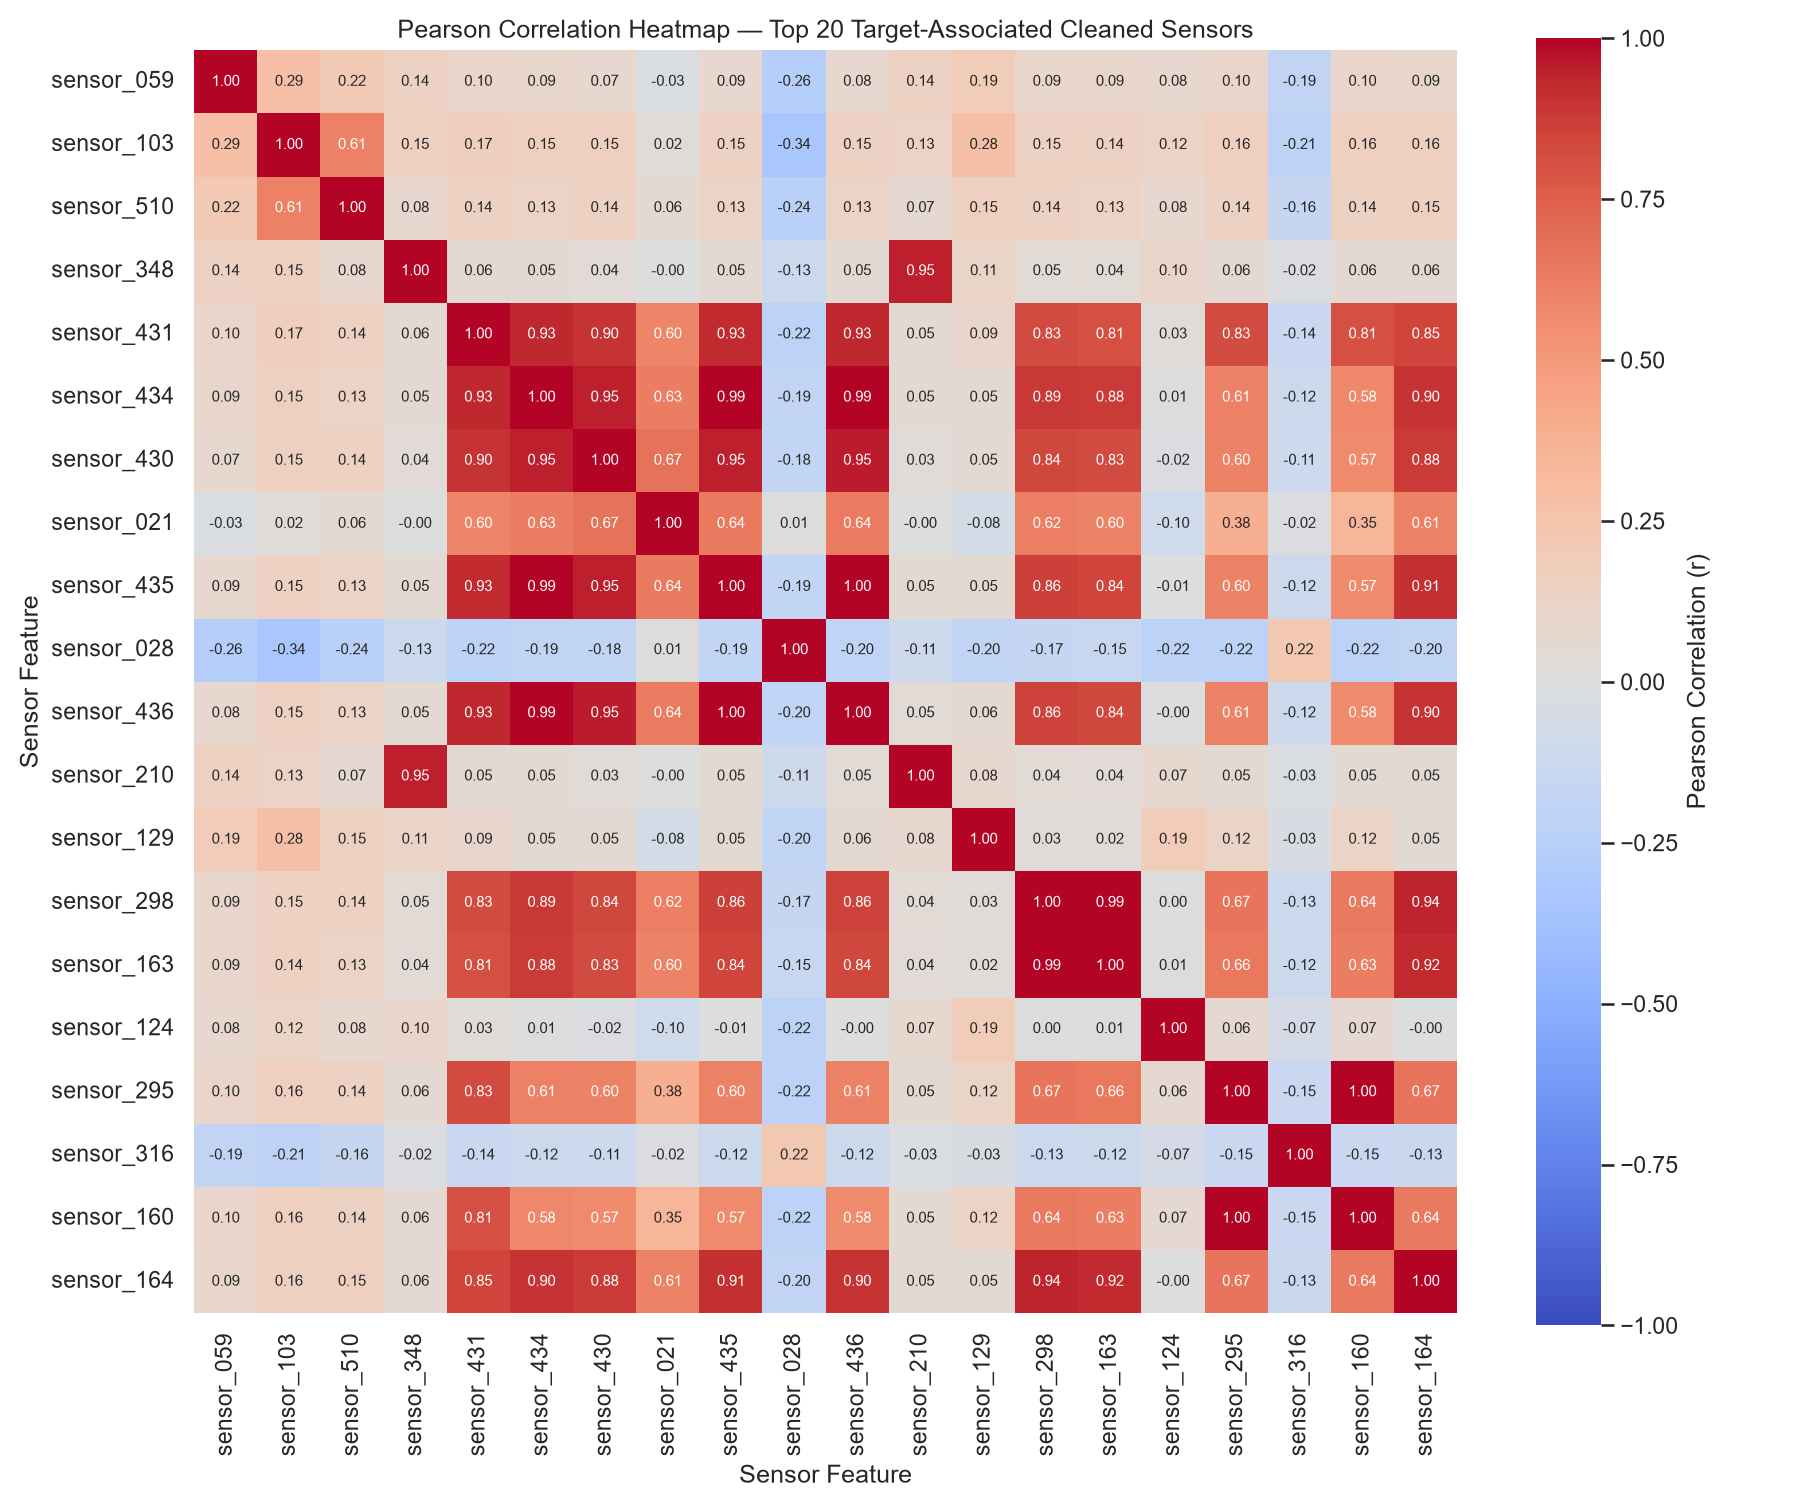

In [10]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/correlation_heatmap.png')))

**Interpretation (`correlation_heatmap.png`):** Strong collinear blocks appear among target-associated features (`sensor_430`–`sensor_436` with `r >= 0.90`, `sensor_160`/`sensor_295` at `r = 1.00`), highlighting redundant sensor channels.

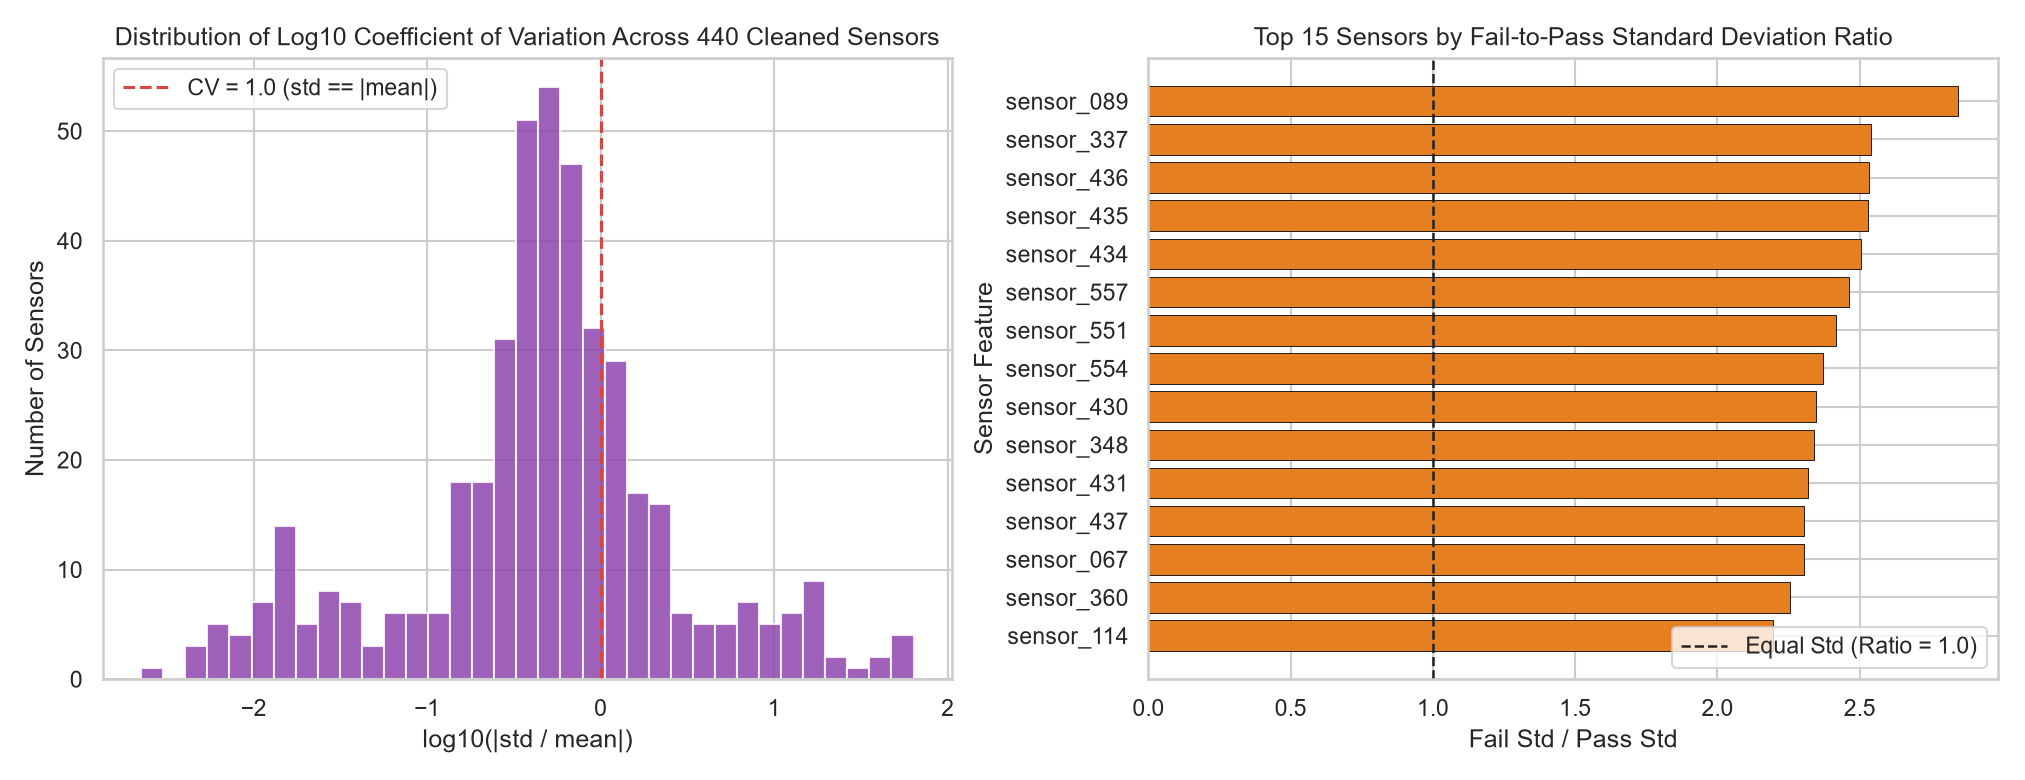

In [11]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/feature_variability.png')))

**Interpretation (`feature_variability.png`):** `122` sensors have `|std / mean| > 1.0`, and top dispersion-ratio sensors show more than `2.2x` higher standard deviation in Fail wafers than Pass wafers.

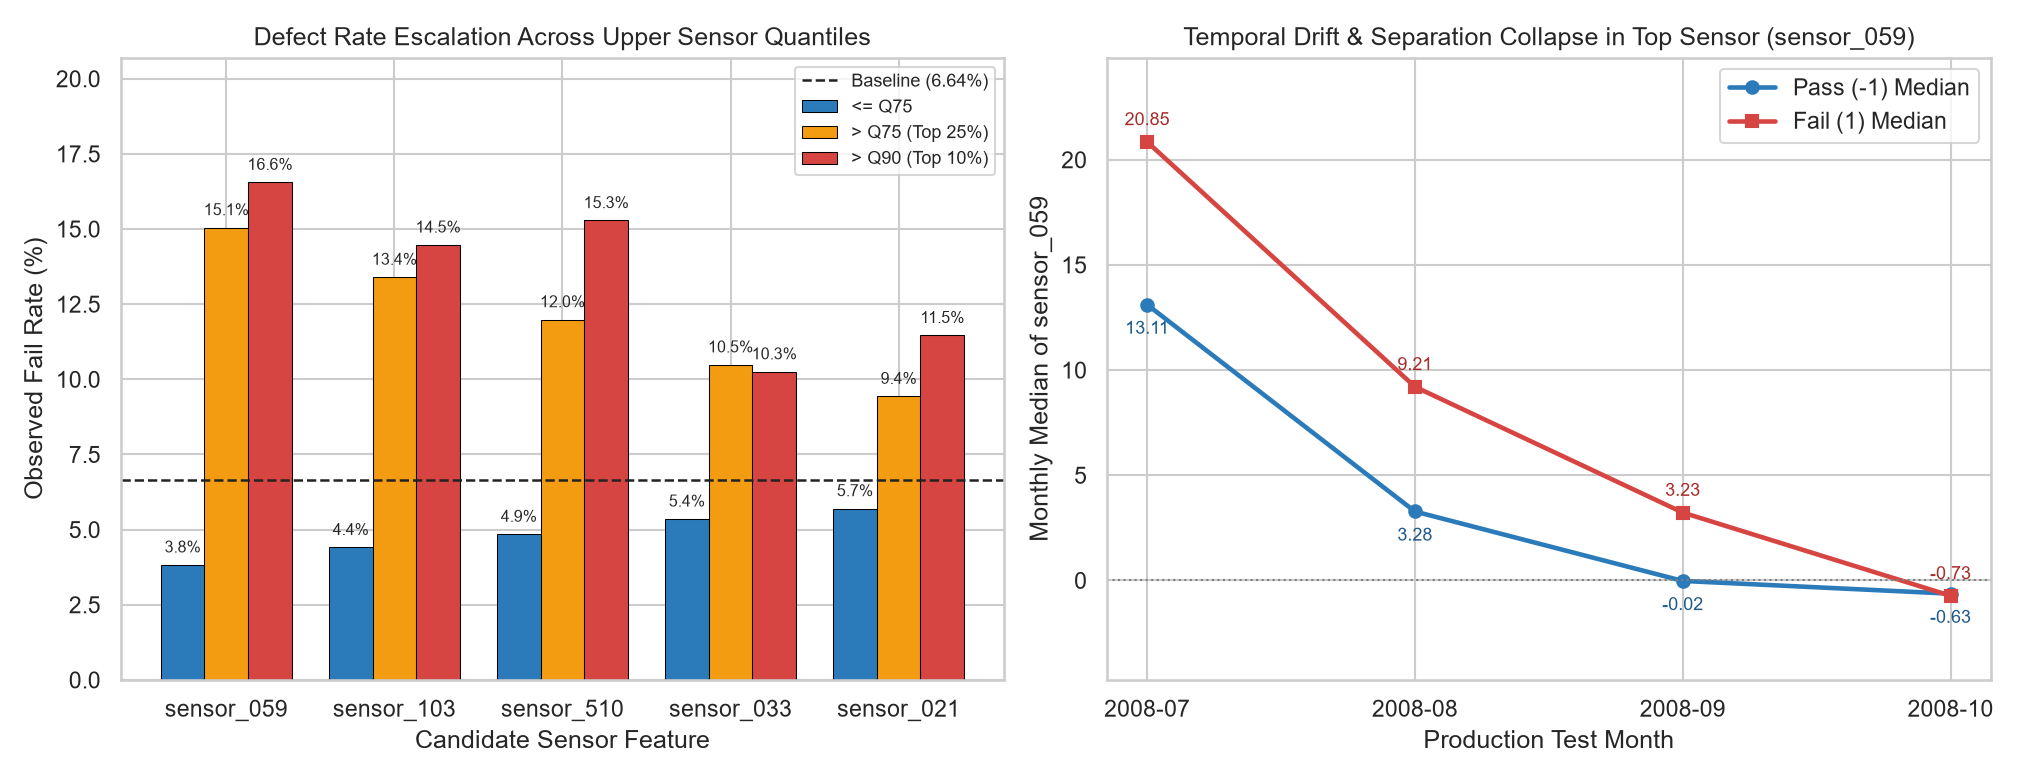

In [12]:
display(Image(filename=str(PROJECT_ROOT / 'reports/figures/pass_fail_sensor_comparison.png')))

**Interpretation (`pass_fail_sensor_comparison.png`):** Defect rates climb in upper quantiles (`sensor_059`: `3.8%` `<=Q75` to `16.6%` `>Q90`), yet `sensor_059` drifts monotonically downward across months and loses separation in October 2008.